# 04. Дообучение MobileNetV3-Small для конкретных POI

Задача: поднять true accept при ограниченном FAR. Веса обучаются только на positive-train.
Negative-val используется для выбора эпохи и порогов, negative-test — только для оценки.
Прежние модели и исходные фотографии сохраняются.
Эксперимент не гарантирует достижения 85%; результат фиксируется до просмотра test.


In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image as DisplayImage
ROOT=Path.cwd().resolve()
if not (ROOT/'config/mobilenetv3_finetune.json').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.poi_finetune import train_model,FinetunedPOIVerifier
from src.poi_baseline import sha256_file
OUTPUT=ROOT/'models/mobilenetv3_finetuned'
CONFIG=ROOT/'config/mobilenetv3_finetune.json'
display(pd.Series(json.loads(CONFIG.read_text())))


I:\Невидаль\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seed                                                               42
threads                                                             4
max_epochs                                                         18
patience                                                            5
classes_per_batch                                                   8
images_per_class                                                    3
steps_per_epoch                                                    30
encoder_learning_rate                                          0.0001
head_learning_rate                                              0.001
weight_decay                                                   0.0001
unfreeze_last_blocks                                                4
contrastive_weight                                               0.15
contrastive_temperature                                           0.1
cosine_logit_scale                                               16.0
gallery_max_per_poi 

## 1. Протокол обучения

ImageNet1K V1 → последние четыре блока Small; BatchNorm frozen.
Сбалансированные батчи: 8 POI × 3 независимых фото. Loss: cosine classification CE + 0.15 SupCon.
Умеренные аугментации применяются только к train после разделения.
Preprocessing сохраняет весь кадр: EXIF → JPEG draft 640 → thumbnail 320 → letterbox 224.
В каждой эпохе заново строится train-галерея и калибруется отказ на validation.
Сравниваются identity, центрирование и регуляризованное PCA-whitening до 128D;
среднее и матрица преобразования вычисляются только из positive-train эмбеддингов.
Выбор checkpoint: максимальный val true accept при ограничениях FAR, затем macro-F1 и accuracy.
Точка epoch 0 — контроль frozen encoder с тем же новым preprocessing.
Test-фото декодируются только после фиксации эпохи и порогов.

Run All повторно использует завершённый выпуск с проверкой хэшей. Новый эксперимент требует другой OUTPUT.


best_epoch                                                                     0
selection_split                                             val_and_negative_val
test_used_for_selection                                                    False
selected_validation_metrics    {'accuracy': 0.7086092715231788, 'macro_f1': 0...
selection_objective                   val_true_accept_at_fixed_far_then_macro_f1
weights_source_sha256          047dcff4addef86ea5bc2eff13c9614dc11f47ab1160d0...
dtype: object

,epoch,loss,accuracy,macro_f1,true_accept_rate,external_any_poi_far,known_hard_wrong_far,embedding_transform,elapsed_seconds
0,0,NaN,0.708609,0.669056,0.198675,0.006981,0.0,identity,NaN
1,1,3.103034,0.695364,0.643609,0.079470,0.001745,0.0,pca128_whiten,21.453
2,2,1.666398,0.728477,0.688158,0.006623,0.000000,0.0,center,23.578
3,3,1.127159,0.807947,0.765337,0.006623,0.000000,0.0,pca128_whiten,22.688
4,4,0.981989,0.814570,0.770435,0.052980,0.008726,0.0,identity,21.750
5,5,0.828578,0.801325,0.756315,0.052980,0.008726,0.0,identity,21.234


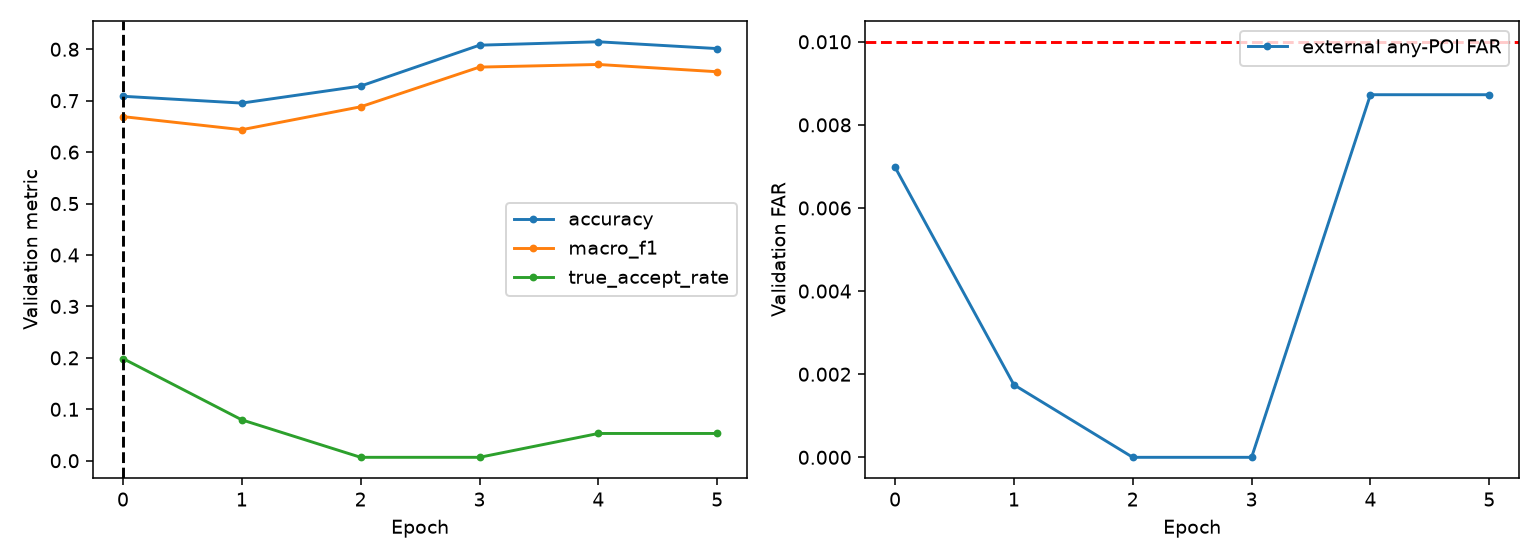

In [2]:
if not OUTPUT.exists():
    metadata,metrics=train_model(ROOT,OUTPUT,CONFIG)
else:
    assert (OUTPUT/'metadata.json').exists(), 'Обучение ещё не завершено; дождитесь CLI'
    metadata=json.loads((OUTPUT/'metadata.json').read_text())
    assert json.loads(CONFIG.read_text())==json.loads((OUTPUT/'config.json').read_text()),'Конфигурация изменена: нужен новый выпуск'
    for name,digest in metadata['artifact_sha256'].items():assert sha256_file(OUTPUT/name)==digest,name
    for name,digest in metadata['input_split_sha256'].items():assert sha256_file(ROOT/f'data/annotations/{name}.csv')==digest,name
    metrics=json.loads((OUTPUT/'metrics.json').read_text())
selection=json.loads((OUTPUT/'selection.json').read_text())
display(pd.Series(selection))
display(pd.read_csv(OUTPUT/'training_history.csv'))
display(DisplayImage(filename=str(ROOT/'reports/mobilenetv3_finetuned/training_curves.png')))


## 2. Отложенная оценка

Accuracy/macro-F1 ниже описывают выбор лидирующего POI без отказа. True accept дополнительно
учитывает прохождение порогов. External FAR считает любое подтверждение одного из 23 POI на постороннем фото.
Изменения по диагностическому test не используются для повторного выбора checkpoint или порогов.


In [3]:
table=[]
for name in ['val','test']:
    table.append({'split':name, 'accuracy':metrics[name]['accuracy'],'macro_f1':metrics[name]['macro_f1'],
                  'true_accept':metrics[name]['true_accept_rate'],'hard_wrong_far':metrics[name]['hard_wrong_far'],
                  'external_any_poi_far':metrics[f'negative_{name}']['any_poi_far']})
display(pd.DataFrame(table))
display(pd.read_csv(OUTPUT/'test_per_poi.csv'))
display(pd.read_csv(OUTPUT/'negative_test_groups.csv'))


,split,accuracy,macro_f1,true_accept,hard_wrong_far,external_any_poi_far
0,val,0.708609,0.669056,0.198675,0.000000,0.006981
1,test,0.650685,0.610912,0.109589,0.006849,0.012216


,poi_id,query_count,top1_accuracy,true_accept_rate,known_wrong_far,true_accepts,wrong_accepts
0,moscow/arbat/arseny_morozov_house,7,0.714286,0.142857,0.000000,1,0
1,moscow/arbat/pashkov_house,7,0.714286,0.285714,0.000000,2,0
2,moscow/khamovniki/khrushchev_seleznev_house,5,0.600000,0.000000,0.000000,0,0
3,moscow/khamovniki/pushkin_museum,6,0.500000,0.166667,0.000000,1,0
4,moscow/ostankinskiy/armenia,6,0.666667,0.000000,0.000000,0,0
5,moscow/ostankinskiy/central_pavilion,6,0.833333,0.000000,0.000000,0,0
6,moscow/ostankinskiy/cosmos,7,0.857143,0.428571,0.000000,3,0
7,moscow/ostankinskiy/main_entrance,7,0.714286,0.000000,0.007194,0,1
8,moscow/ostankinskiy/moscow_sun,8,0.750000,0.250000,0.000000,2,0
9,moscow/ostankinskiy/ostankino_tower,10,0.700000,0.200000,0.000000,2,0


,group_by,group,images,false_accepts,any_poi_far
0,negative_type,similar_arch,48,0,0.000000
1,negative_type,similar_classical_building,100,1,0.010000
2,negative_type,similar_decorated_building,50,0,0.000000
3,negative_type,similar_hotel,98,1,0.010204
4,negative_type,similar_mansion,50,0,0.000000
5,negative_type,similar_pavilion,177,5,0.028249
6,negative_type,similar_tower,50,0,0.000000
7,source_poi_id,moscow/aeroport/petrovsky_palace,50,0,0.000000
8,source_poi_id,moscow/donskoy/shukhov_tower,50,0,0.000000
9,source_poi_id,moscow/dorogomilovo/hotel_ukraina,50,1,0.020000


## 3. Локальная верификация

Загрузчик использует дообученные encoder.pt, новую галерею и соответствующие пороги/preprocessing.
Автоматического переключения прежней версии приложения не выполняется.


In [4]:
verifier=FinetunedPOIVerifier(OUTPUT)
test=pd.read_csv(OUTPUT/'splits/test.csv',keep_default_na=False)
example=test.iloc[0]
display(pd.Series(verifier.verify(ROOT/example.file_path,example.poi_id)))
# verifier.verify(Path('path/to/photo.jpg'),'moscow/ostankinskiy/ostankino_tower')


accepted                                                             False
reason                                                     poi_not_matched
target_poi_id                moscow/ostankinskiy/friendship_of_the_peoples
predicted_poi_id                         moscow/ostankinskiy/main_entrance
score                                                             0.680478
margin                                                            -0.17802
score_is_probability                                                 False
reference_image_id                                 manual_b4ca62ac1323b1bb
reference_source                                                    manual
reference_author                                             Shilkova A.M.
reference_licence                                            Public Domain
reference_version                                8c54b2863887-950b5e0708bf
threshold_version                                         b3efb4f4c8d44afd
preprocessing_version    

## 4. Ограничения и отчёт

Малые классы и повторное использование val ограничивают уверенность в качестве.
Положительный test уже служил диагностике предыдущих экспериментов; нужен новый закрытый полевой набор.
Negative-test не покрывает все редкие типы. Источники, авторы и лицензии сохранены в splits и галерее.

[Transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).
[Supervised contrastive learning](https://arxiv.org/abs/2004.11362).


In [5]:
display(Markdown((ROOT/'reports/mobilenetv3_finetuned/summary.md').read_text(encoding='utf-8')))


# Дообучение MobileNetV3-Small для POI

Выбранная эпоха: 0; выбор только по positive-val и negative-val. Веса обучались только на positive-train.
Сбалансированные P×K батчи, cosine classification + SupCon; последние блоки backbone; BatchNorm заморожен.
Preprocessing: EXIF → JPEG draft 640 → thumbnail 320 → letterbox 224 → ImageNet normalization. Метрика: identity, fit только positive-train; галерея только train.

| Модель / test | Accuracy без отказа | Macro-F1 без отказа | True accept | External any-POI FAR |
|---|---:|---:|---:|---:|
| Frozen Small + строгий отказ | 74.66% | 73.26% | 25.34% | 0.87% |
| Выбранный эксперимент | 65.07% | 61.09% | 10.96% | 1.22% |

## Наблюдение → интерпретация → действие
- Верных подтверждений 16/146 → текущий true accept=10.96% → цель 85% пока не достигнута.
- Внешних ошибочных подтверждений 7/573 → отказ измерен на Commons landmarks → не переносить результат на произвольную мобильную съёмку.
- Выбор эпохи и порогов выполнялся на одном validation → его оценки оптимистичны → ориентироваться на отложенную оценку, а окончательное качество подтверждать новым закрытым полевым test.
- Малые классы содержат единичные val/test фото → оценки нестабильны и возможен переучёт → добрать независимые ракурсы, особенно малые классы.
- Условия FAR заданы для validation → test может превысить ограничение → не подбирать пороги повторно по test.
- Preprocessing и веса изменились одновременно → прирост общего эксперимента не доказывает вклад одного изменения → epoch 0 в training_history.csv фиксирует frozen-encoder контроль с новым preprocessing.
- Источники, авторы и лицензии сохранены в snapshots splits и gallery.csv → происхождение доступно для каждого эталона → сохранять атрибуцию при дальнейшем экспорте.

Исходники, положительные/отрицательные splits и прежние версии моделей не изменялись. Новый выпуск экспериментальный.
[PyTorch: transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).
[SupCon](https://arxiv.org/abs/2004.11362).
